In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

# Retina display
%config InlineBackend.figure_format = 'retina'

In [ ]:
from tueplots import bundles
plt.rcParams.update(bundles.beamer_moml())


# Also add despine to the bundle using rcParams
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False

# Increase font size to match Beamer template
plt.rcParams['font.size'] = 16
# Make background transparent
plt.rcParams['figure.facecolor'] = 'none'

In [ ]:
prior_mu = torch.zeros(2)
prior_cov = torch.eye(2)
theta = torch.distributions.MultivariateNormal(prior_mu, prior_cov)
theta

In [ ]:
theta.loc, theta.covariance_matrix

In [ ]:
# Plot the prior in 2d contour

theta1 = torch.linspace(-3, 3, 100)
theta2 = torch.linspace(-3, 3, 100)

theta1, theta2 = torch.meshgrid(theta1, theta2)

theta_values = torch.stack((theta1, theta2), dim=-1)  # Shape: (100, 100, 2)

z = theta.log_prob(theta_values.view(-1, 2))  # Shape: (10000,)
z = z.view(100, 100)  # Reshape to (100, 100)

plt.contourf(theta1.numpy(), theta2.numpy(), z.numpy(), 20)
plt.gca().set_aspect('equal')

plt.colorbar()


In [ ]:
theta_sample = theta.sample((1000,))
theta_sample

In [ ]:
x_lin = torch.linspace(-5, 5, 100)
y_lin = theta_sample[:, 0].unsqueeze(1) + theta_sample[:, 1].unsqueeze(1) * x_lin.unsqueeze(0)

In [ ]:
_ = plt.plot(x_lin.numpy(), y_lin.numpy().T, alpha=0.1, color='red')


In [ ]:
# Mean prediction
y_pred_mean = y_lin.mean(dim=0)
plt.plot(x_lin.numpy(), y_pred_mean.numpy(), color='red', linewidth=3)

# 95% confidence interval
y_pred_std = y_lin.std(dim=0)
plt.fill_between(x_lin.numpy(), (y_pred_mean - 2 * y_pred_std).numpy(), (y_pred_mean + 2 * y_pred_std).numpy(), alpha=0.3, color='red', label='95% confidence interval')
plt.ylim(-12, 12)
plt.legend()


In [ ]:
# Plot the theta samples on the contour plot as scatter points

plt.contourf(theta1.numpy(), theta2.numpy(), z.numpy(), 4, alpha=0.5)
plt.gca().set_aspect('equal')
plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')

plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.scatter(theta_sample[:, 0].numpy(), theta_sample[:, 1].numpy(), alpha=0.1, color='black')
plt.tight_layout()

# Closed form solution for prior predictive distribution

![CleanShot 2023-06-05 at 17.47.27@2x.png](<attachment:CleanShot 2023-06-05 at 17.47.27@2x.png>)
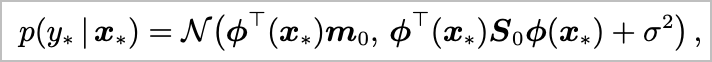

In [ ]:
### Noiseless case

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Define the prior parameters
m0 = torch.tensor([0.0, 0.0])  # Mean of the prior
S0 = torch.tensor([[1.0, 0.0], [0.0, 1.0]])  # Covariance matrix of the prior
sigma = 0.0  # Noise parameter

# Define the basis function (phi)
def phi(x):
    return torch.tensor([1.0, x])

# Function to calculate the prior predictive distribution
def prior_predictive(x_star, m0, S0, sigma):
    phi_x_star = torch.stack([phi(x) for x in x_star])
    predictive_mean = phi_x_star @ m0
    predictive_cov = torch.diagonal(phi_x_star @ S0 @ phi_x_star.t(), offset=0) + sigma**2
    return predictive_mean, predictive_cov

# Generate x values for prediction
x_star = torch.linspace(-5, 5, 100)

# Calculate the prior predictive distribution
predictive_mean, predictive_cov = prior_predictive(x_star, m0, S0, sigma)

# Plot mean +- 2 std
plt.plot(x_star.numpy(), predictive_mean.numpy(), color='red', linewidth=3)
plt.fill_between(x_star.numpy(), (predictive_mean - 2 * torch.sqrt(predictive_cov)).numpy(), (predictive_mean + 2 * torch.sqrt(predictive_cov)).numpy(), alpha=0.3, color='red', label='95% confidence interval')
plt.legend()
plt.ylim(-12, 12)


In [ ]:
y_pred_std

In [ ]:
torch.sqrt(predictive_cov)

### Computing the evidence term


$$ I = \int p(\mathcal{D} \mid \theta) p(\theta) \mathrm{d}\theta $$

$$ I \approx \frac{1}{N} \sum_{i=1}^N p(\mathcal{D} \mid \theta_i) $$

where $\theta_i \sim p(\theta)$


In [ ]:
theta

In [ ]:
theta.sample((10,))

In [ ]:
def forward(x, theta):
    return theta[:, 0].unsqueeze(1) + theta[:, 1].unsqueeze(1) * x.unsqueeze(0)

def likelihood(y, x, theta, sigma):
    return torch.distributions.Normal(forward(x, theta), sigma).log_prob(y).sum(dim=1)




In [ ]:
# Use a different prior distribution: a mixture of two Gaussians

pis = torch.tensor([0.7, 0.3])
norm1 = torch.distributions.MultivariateNormal(torch.tensor([0.0, 0.0]), torch.tensor([[2.0, 0.5], [0.5, 1.0]]))
norm2 = torch.distributions.MultivariateNormal(torch.tensor([3.0, -2.0]), torch.tensor([[1.0, 0.0], [0.0, 2.0]]))

mog = torch.distributions.MixtureSameFamily(torch.distributions.Categorical(pis), 
                                            torch.distributions.MultivariateNormal(torch.stack((norm1.loc, norm2.loc)),
                                             torch.stack((norm1.covariance_matrix, norm2.covariance_matrix))))

theta = mog.sample((1000,))

# Plot the samples


# Plot the prior in 2d contour

theta1 = torch.linspace(-8, 8, 100)
theta2 = torch.linspace(-8, 8, 100)

theta1, theta2 = torch.meshgrid(theta1, theta2)

theta_values = torch.stack((theta1, theta2), dim=-1)  # Shape: (100, 100, 2)

z = mog.log_prob(theta_values.view(-1, 2))  # Shape: (10000,)
z = z.view(100, 100)  # Reshape to (100, 100)

plt.contourf(theta1.numpy(), theta2.numpy(), z.numpy(), 20)
plt.gca().set_aspect('equal')

plt.scatter(theta[:, 0].numpy(), theta[:, 1].numpy(), alpha=0.1, color='black')



In [ ]:
theta_sample = mog.sample((1000,))
y_lin = theta_sample[:, 0].unsqueeze(1) + theta_sample[:, 1].unsqueeze(1) * x_lin.unsqueeze(0)

In [ ]:
_ = plt.plot(x_lin.numpy(), y_lin.numpy().T, alpha=0.01, color='black')

# Plot the last sample to see the line and mark the label
_ = plt.plot(x_lin.numpy(), y_lin.numpy()[-1], alpha=0.01, color='black', label='Samples')

# Mean prediction
y_pred_mean = y_lin.mean(dim=0)
plt.plot(x_lin.numpy(), y_pred_mean.numpy(), color='red', linewidth=3)

# 95% confidence interval
y_pred_std = y_lin.std(dim=0)
plt.fill_between(x_lin.numpy(), (y_pred_mean - 2 * y_pred_std).numpy(), (y_pred_mean + 2 * y_pred_std).numpy(), alpha=0.3, color='red', label='95% confidence interval')

plt.legend()